In [1]:
!mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.853 seconds
  Name    Version  Build                Channel
-------------------------------------------------------------
+ pandas  3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
- pip     26.2.2   pyh145f28c_0         conda-forge


In [2]:
!mamba install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.367 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ six           1.17.0   pyhe01879c_1         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

print("Библиотеки успешно импортированы")

Библиотеки успешно импортированы


In [4]:
# Список файлов с заказами
orders_files = [
    "orders_2024_01.csv",
    "orders_2024_02.csv",
    "orders_2024_03.csv"
]

# Проверяем расположение файлов
if all(os.path.exists(f) for f in orders_files):
    paths = orders_files
elif all(os.path.exists(os.path.join("data", f)) for f in orders_files):
    paths = [os.path.join("data", f) for f in orders_files]
else:
    raise FileNotFoundError(
        "Не удалось найти CSV-файлы. Проверь расположение файлов."
    )

# Загружаем и объединяем данные
df_orders = pd.concat(
    [pd.read_csv(f) for f in paths],
    ignore_index=True
)

print("Размер таблицы:", df_orders.shape)

display(df_orders.head())

Размер таблицы: (15000, 7)


,order_id,user_id,order_datetime,product_id,price,quantity,status
0,1,1044,2024-01-03 18:39:26,26,14038.15,1,refunded
1,2,1079,2024-01-03 17:45:43,16,9172.60,1,paid
2,3,1041,2024-01-06 22:46:38,25,9035.26,2,paid
3,4,1083,2024-01-08 21:03:51,9,15234.33,3,paid
4,5,1068,2024-01-03 23:26:53,24,4134.38,2,paid


In [5]:
# Преобразуем дату заказа
df_orders["order_datetime"] = pd.to_datetime(
    df_orders["order_datetime"],
    errors="coerce"
)

# Преобразуем числовые признаки
df_orders["price"] = pd.to_numeric(
    df_orders["price"],
    errors="coerce"
)

df_orders["quantity"] = pd.to_numeric(
    df_orders["quantity"],
    errors="coerce"
)

# Рассчитываем выручку
df_orders["revenue"] = (
    df_orders["price"] * df_orders["quantity"]
)

# Создаём признак дня недели
df_orders["weekday"] = (
    df_orders["order_datetime"].dt.day_name()
)

# Удаляем строки без необходимых данных
df_orders = df_orders.dropna(
    subset=["weekday", "revenue"]
)

# Переводим названия дней недели на русский язык
weekday_map = {
    "Monday": "Понедельник",
    "Tuesday": "Вторник",
    "Wednesday": "Среда",
    "Thursday": "Четверг",
    "Friday": "Пятница",
    "Saturday": "Суббота",
    "Sunday": "Воскресенье"
}

df_orders["weekday"] = df_orders["weekday"].map(
    weekday_map
)

# Устанавливаем правильный порядок дней недели
weekday_order = [
    "Понедельник",
    "Вторник",
    "Среда",
    "Четверг",
    "Пятница",
    "Суббота",
    "Воскресенье"
]

df_orders["weekday"] = pd.Categorical(
    df_orders["weekday"],
    categories=weekday_order,
    ordered=True
)

print("Данные подготовлены")
display(df_orders.head())

Данные подготовлены


,order_id,user_id,order_datetime,product_id,price,quantity,status,revenue,weekday
0,1,1044,2024-01-03 18:39:26,26,14038.15,1,refunded,14038.15,Среда
1,2,1079,2024-01-03 17:45:43,16,9172.60,1,paid,9172.60,Среда
2,3,1041,2024-01-06 22:46:38,25,9035.26,2,paid,18070.52,Суббота
3,4,1083,2024-01-08 21:03:51,9,15234.33,3,paid,45702.99,Понедельник
4,5,1068,2024-01-03 23:26:53,24,4134.38,2,paid,8268.76,Среда


In [6]:
# Группировка данных по дням недели
weekday_revenue = df_orders.groupby(
    "weekday",
    observed=False
)["revenue"].agg(
    sum="sum",
    mean="mean",
    median="median",
    std="std"
)

print("Статистика выручки по дням недели:")

display(weekday_revenue.round(2))

Статистика выручки по дням недели:


,sum,mean,median,std
weekday,,,,
Понедельник,54583476.25,25686.34,19720.49,19538.83
Вторник,54367341.28,25644.97,19860.44,19360.91
Среда,56239823.84,26097.37,19984.48,19482.70
Четверг,57784092.43,25613.52,19320.44,19270.04
Пятница,52936489.64,25147.98,19223.13,19193.14
Суббота,55239314.42,25909.62,19889.70,19080.41
Воскресенье,53393113.93,25340.82,19449.16,19395.32


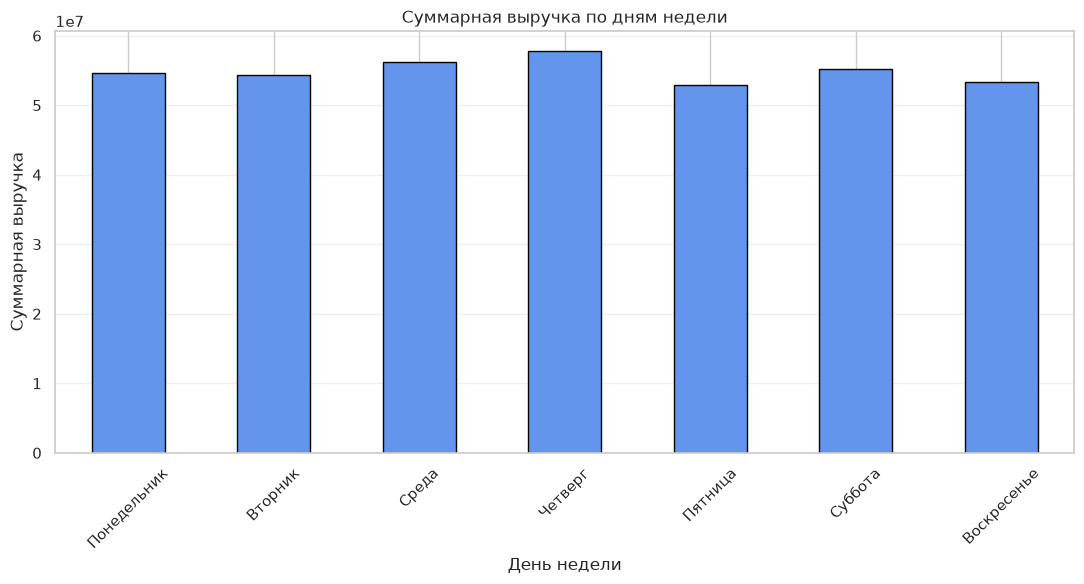

In [7]:
plt.figure(figsize=(11, 6))

weekday_revenue["sum"].plot(
    kind="bar",
    color="cornflowerblue",
    edgecolor="black"
)

plt.title("Суммарная выручка по дням недели")
plt.xlabel("День недели")
plt.ylabel("Суммарная выручка")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

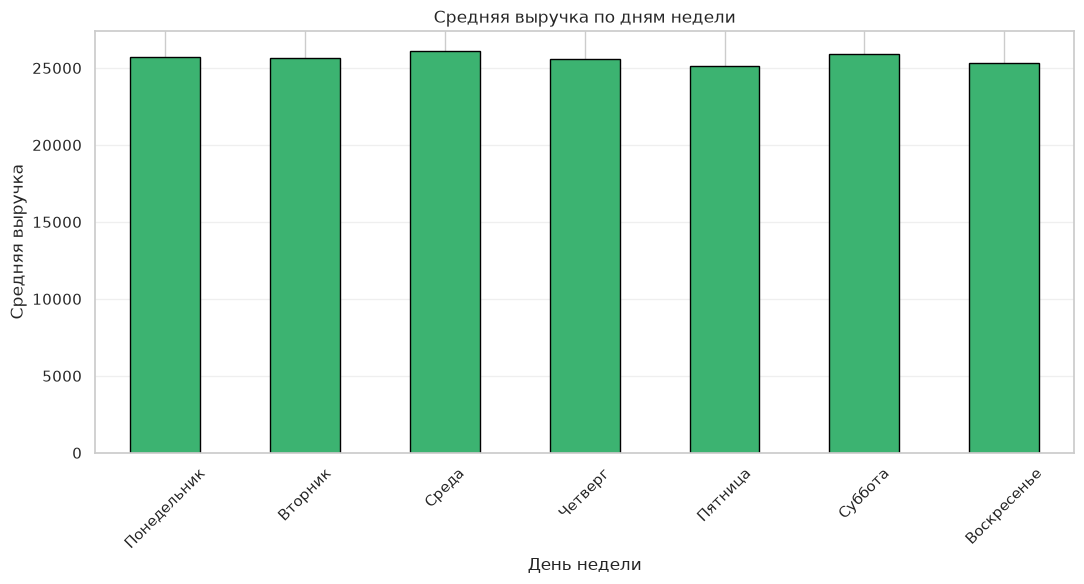

In [8]:
plt.figure(figsize=(11, 6))

weekday_revenue["mean"].plot(
    kind="bar",
    color="mediumseagreen",
    edgecolor="black"
)

plt.title("Средняя выручка по дням недели")
plt.xlabel("День недели")
plt.ylabel("Средняя выручка")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

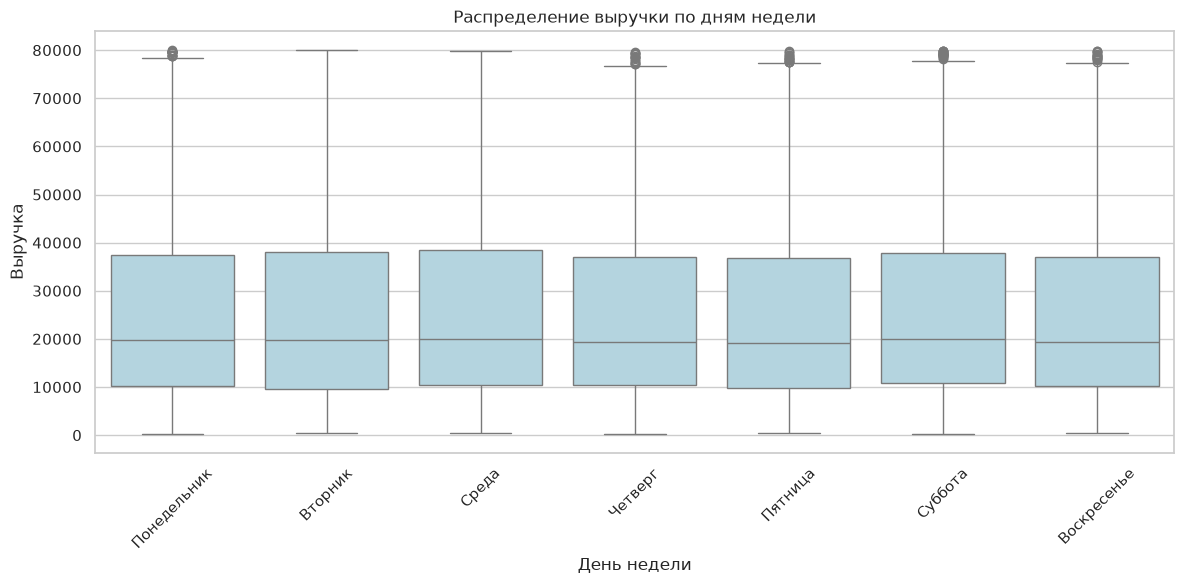

In [9]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_orders,
    x="weekday",
    y="revenue",
    order=weekday_order,
    color="lightblue"
)

plt.title("Распределение выручки по дням недели")
plt.xlabel("День недели")
plt.ylabel("Выручка")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [10]:
# Определяем день с максимальным стандартным отклонением
most_unstable_day = weekday_revenue["std"].idxmax()

max_std = weekday_revenue["std"].max()

print("День с самой нестабильной выручкой:",
      most_unstable_day)

print("Стандартное отклонение:",
      round(max_std, 2))

print("\nСтандартное отклонение по дням недели:")
display(weekday_revenue[["std"]].sort_values(
    by="std",
    ascending=False
).round(2))

День с самой нестабильной выручкой: Понедельник
Стандартное отклонение: 19538.83

Стандартное отклонение по дням недели:


,std
weekday,
Понедельник,19538.83
Среда,19482.70
Воскресенье,19395.32
Вторник,19360.91
Четверг,19270.04
Пятница,19193.14
Суббота,19080.41


In [11]:
weekday_iqr = df_orders.groupby(
    "weekday",
    observed=False
)["revenue"].agg(
    lambda x: x.quantile(0.75) - x.quantile(0.25)
)

print("Межквартильный размах по дням недели:")
display(weekday_iqr.sort_values(
    ascending=False
).round(2))

Межквартильный размах по дням недели:


weekday
Вторник        28358.98
Среда          28132.45
Понедельник    27272.62
Пятница        27026.55
Воскресенье    26894.75
Суббота        26892.78
Четверг        26606.04
Name: revenue, dtype: float64

In [12]:
# День с максимальной суммарной выручкой
max_sum_day = weekday_revenue["sum"].idxmax()

# День с максимальной средней выручкой
max_mean_day = weekday_revenue["mean"].idxmax()

# День с максимальной медианной выручкой
max_median_day = weekday_revenue["median"].idxmax()

# Вывод результатов
print("АНАЛИТИЧЕСКИЕ ВЫВОДЫ\n")

print(
    f"1. Наибольшая суммарная выручка наблюдается "
    f"в день недели: {max_sum_day}. "
    f"Её значение составляет "
    f"{weekday_revenue.loc[max_sum_day, 'sum']:.2f}."
)

print(
    f"\n2. Наибольшая средняя выручка зафиксирована "
    f"в день недели: {max_mean_day}. "
    f"Её значение составляет "
    f"{weekday_revenue.loc[max_mean_day, 'mean']:.2f}."
)

print(
    f"\n3. Наиболее нестабильная выручка наблюдается "
    f"в день недели: {most_unstable_day}. "
    f"Стандартное отклонение составляет "
    f"{max_std:.2f}."
)

print(
    f"\nДополнительно: наибольшая медианная выручка "
    f"наблюдается в день: {max_median_day}."
)

АНАЛИТИЧЕСКИЕ ВЫВОДЫ

1. Наибольшая суммарная выручка наблюдается в день недели: Четверг. Её значение составляет 57784092.43.

2. Наибольшая средняя выручка зафиксирована в день недели: Среда. Её значение составляет 26097.37.

3. Наиболее нестабильная выручка наблюдается в день недели: Понедельник. Стандартное отклонение составляет 19538.83.

Дополнительно: наибольшая медианная выручка наблюдается в день: Среда.
